In [1]:
import os
print(os.listdir())

['.anaconda', '.arduinoIDE', '.conda', '.continuum', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.streamlit', '.VirtualBox', '.vscode', '.vscode-shared', '3D Objects', 'Advance-Functions.ipynb', 'anaconda_projects', 'analysis', 'app.py', 'AppData', 'Application Data', 'books_data.csv', 'charts.py', 'CNN(lab work).ipynb', 'Contacts', 'Cookies', 'dashboard.ipynb', 'data', 'Documents', 'Downloads', 'Favorites', 'filters.py', 'if-else (1).ipynb', 'images.png', 'IntelGraphicsProfiles', 'Lec-3.02(NumPy-02-Array-vs-List).ipynb', 'Lec-3.03(NumPy-03-BasicOperations).ipynb', 'Lec-3.04(NumPy-04-Array-Indexing-and-Slicing).ipynb', 'Lec-3.05(NumPy-05-BroadcastingandReshaping).ipynb', 'Lec-3.06(NumPy-06-ArrayManipulation).ipynb', 'Lec-3.09(Pandas-01-From-Python-Dictionary-to-Pandas-Dataframe).ipynb', 'Links', 'Local Settings', 'loops.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{d1ed1e3d-224d-11f1-8d8f-801934

In [1]:
%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.85.1-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp313-cp313-win_amd64.whl.metadata (2.7 kB)
  Using c

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [2]:
import sys
print(sys.version)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras import models, layers

In [4]:
df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("Train shape:", df.shape)      # expect (42000, 785)
print("Test shape:", test_df.shape)  # expect (28000, 784)
df.head()

Train shape: (42000, 785)
Test shape: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
y = df.iloc[:, 0].values
X = df.iloc[:, 1:].values.astype("float32") / 255.0
X = X.reshape(-1, 28, 28, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Validation:", X_val.shape)

Train: (33600, 28, 28, 1)  Validation: (8400, 28, 28, 1)


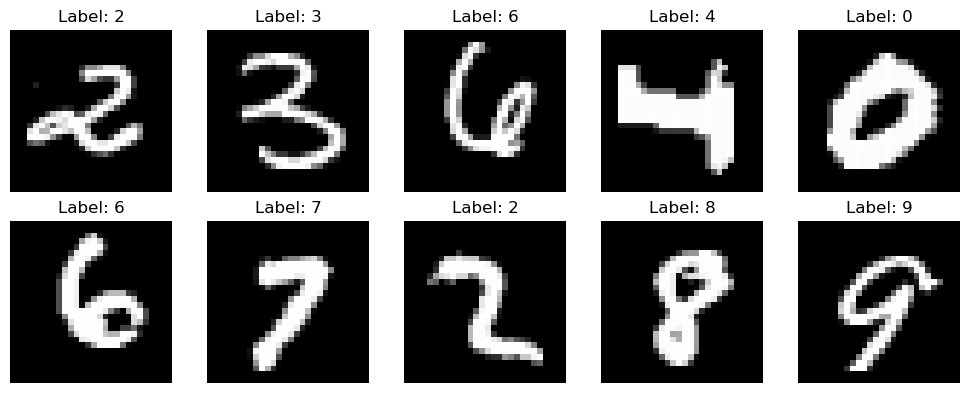

In [6]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3)),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3)),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(10),
    layers.Activation("softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 26, 26, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 11, 11, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 10)                  │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
)

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.9156 - loss: 0.2765 - val_accuracy: 0.9729 - val_loss: 0.0826
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9745 - loss: 0.0838 - val_accuracy: 0.9762 - val_loss: 0.0732
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9822 - loss: 0.0564 - val_accuracy: 0.9848 - val_loss: 0.0477
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9851 - loss: 0.0475 - val_accuracy: 0.9857 - val_loss: 0.0482
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9885 - loss: 0.0369 - val_accuracy: 0.9873 - val_loss: 0.0425
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.9901 - loss: 0.0291 - val_accuracy: 0.9892 - val_loss: 0.0368
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.9918 - loss: 0.0257 - val_accuracy: 0.9890 - val_loss: 0.0409
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9925 - loss: 0.0233 - 

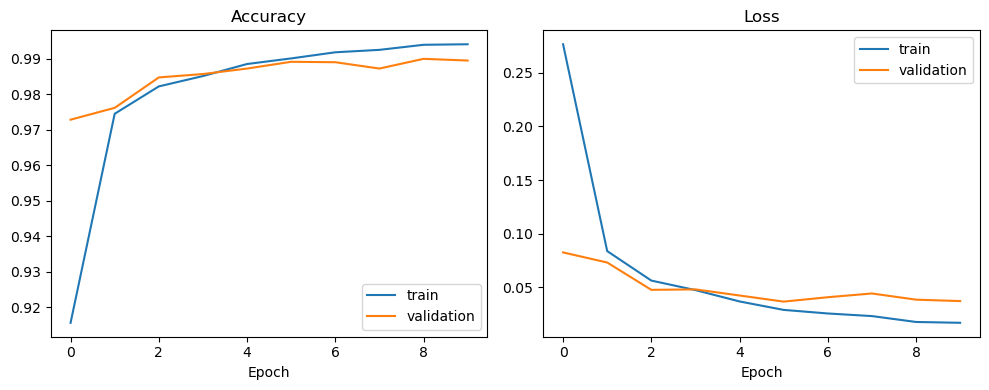

In [10]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.show()

In [11]:
X_test = test_df.values.astype("float32").reshape(-1, 28, 28, 1) / 255.0
preds = np.argmax(model.predict(X_test), axis=1)

submission = pd.DataFrame({"ImageId": np.arange(1, len(preds) + 1), "Label": preds})
submission.to_csv("submission.csv", index=False)
submission.head()

875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,9
4,5,3


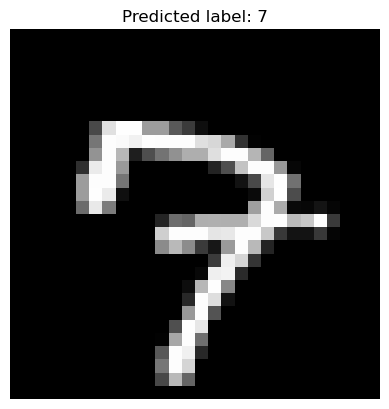

Predicted label: 7


In [12]:
X_test = (test_df.values.astype("float32") / 255.0).reshape(-1, 28, 28, 1)

idx = 5   # any image number from 0 to 27999

probs = model.predict(X_test[idx:idx+1], verbose=0)
label = np.argmax(probs)

plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
plt.title(f"Predicted label: {label}")
plt.axis("off")
plt.show()

print("Predicted label:", label)

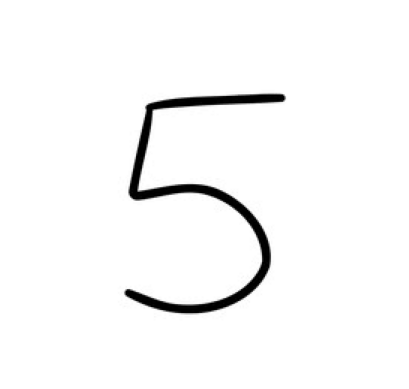

In [13]:
from PIL import Image

img = Image.open("images.png")

plt.imshow(img)
plt.axis("off")
plt.show()